# Task 1 — Netflix Content Recommendation System
### Auspify Technologies | Machine Learning Internship

**Intern:** Krish Nilesh Gurav  
**Task:** Task 1 (Easy) — Netflix Content Recommendation System

## Objective
Build a content-based recommendation system that suggests similar Netflix titles based on genres, categories, and available content attributes.

## Project workflow
1. Load and inspect the dataset.
2. Clean duplicate titles and prepare metadata features.
3. Convert metadata into numerical vectors using TF-IDF.
4. Calculate cosine similarity between titles.
5. Generate recommendations for a selected title.
6. Evaluate recommendation relevance using metadata consistency checks.

**Important dataset limitation:** The supplied CSV does not contain plot summaries, cast details, viewer histories, likes, or watch counts. The model uses only the fields available in the file.

## 1. Import libraries

The project uses Pandas and NumPy for data handling, Scikit-learn for TF-IDF and similarity calculation, and Matplotlib for visualizations.

In [1]:
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from netflix_recommender import NetflixRecommender, _split_values

DATA_PATH = Path("Dataset.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Dataset.csv was not found. Keep it in the same folder as this notebook.")

OUTPUT_DIR = Path("outputs")
CHART_DIR = Path("charts")
OUTPUT_DIR.mkdir(exist_ok=True)
CHART_DIR.mkdir(exist_ok=True)

print("Libraries imported and project folders checked.")

Libraries imported and project folders checked.


## 2. Load and inspect the dataset

The original file contains 8,790 rows and 10 columns. The next cell checks the first records, column types, missing values, and content-type distribution.

In [2]:
raw_data = pd.read_csv(DATA_PATH)
print("Dataset shape:", raw_data.shape)
display(raw_data.head())
print("\nColumn data types:")
display(raw_data.dtypes.rename("data_type").to_frame())
print("\nMissing values per column:")
display(raw_data.isna().sum().rename("missing_values").to_frame())
print("\nContent type counts in original dataset:")
display(raw_data["type"].value_counts().rename_axis("type").to_frame("count"))

Dataset shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"



Column data types:


,data_type
show_id,object
type,object
title,object
director,object
country,object
date_added,object
release_year,int64
rating,object
duration,object
listed_in,object



Missing values per column:


,missing_values
show_id,0
type,0
title,0
director,0
country,0
date_added,0
release_year,0
rating,0
duration,0
listed_in,0



Content type counts in original dataset:


,count
type,
Movie,6126
TV Show,2664


## 3. Clean the data and prepare content features

Repeated title records are removed after trimming title whitespace. Placeholder values such as `Not Given` are treated as unavailable metadata. The model creates weighted feature tokens from:

- Genres/categories (highest weight)
- Director
- Movie or TV Show type
- Country
- Audience rating
- Release decade
- Runtime or number-of-seasons bucket

The title itself is used for searching, not for calculating similarity.

In [3]:
recommender = NetflixRecommender(DATA_PATH)
data = recommender.data

print(f"Original records: {len(raw_data):,}")
print(f"Records after duplicate-title removal: {len(data):,}")
print(f"Duplicate title records removed: {len(raw_data) - len(data):,}")
print(f"TF-IDF feature matrix shape: {recommender.tfidf_matrix.shape}")
print(f"TF-IDF vocabulary size: {len(recommender.vectorizer.vocabulary_):,}")

profile = pd.DataFrame({
    "Item": ["Rows in source dataset", "Unique titles after duplicate-title removal", "Duplicate title records removed", "Columns in source dataset", "TF-IDF vocabulary size"],
    "Value": [len(raw_data), len(data), len(raw_data) - len(data), len(raw_data.columns), len(recommender.vectorizer.vocabulary_)]
})
display(profile)
profile.to_csv(OUTPUT_DIR / "dataset_profile.csv", index=False)

Original records: 8,790
Records after duplicate-title removal: 8,786
Duplicate title records removed: 4
TF-IDF feature matrix shape: (8786, 5146)
TF-IDF vocabulary size: 5,146


,Item,Value
0,Rows in source dataset,8790
1,Unique titles after duplicate-title removal,8786
2,Duplicate title records removed,4
3,Columns in source dataset,10
4,TF-IDF vocabulary size,5146


## 4. Explore the Netflix catalog

### Content type distribution
This chart compares the number of movies and TV shows in the cleaned catalog.

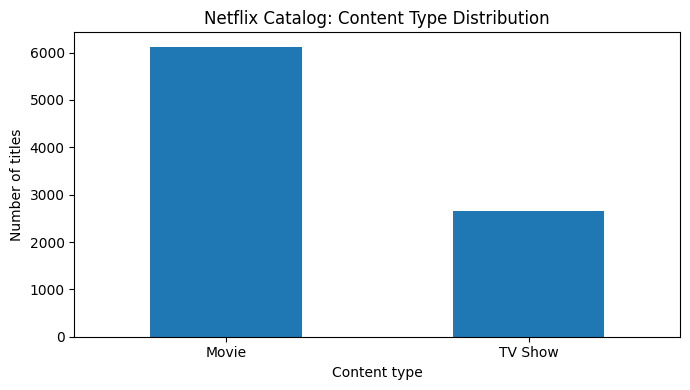

In [4]:
type_counts = data["type"].value_counts()
fig, ax = plt.subplots(figsize=(7, 4))
type_counts.plot(kind="bar", ax=ax)
ax.set_title("Netflix Catalog: Content Type Distribution")
ax.set_xlabel("Content type")
ax.set_ylabel("Number of titles")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(CHART_DIR / "content_type_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

### Most common genres
A title can belong to more than one genre, so each listed genre is counted separately.

,Genre,Title count
0,International Movies,2751
1,Dramas,2423
2,Comedies,1673
3,International TV Shows,1348
4,Documentaries,869
5,Action & Adventure,859
6,TV Dramas,761
7,Independent Movies,755
8,Children & Family Movies,641
9,Romantic Movies,616


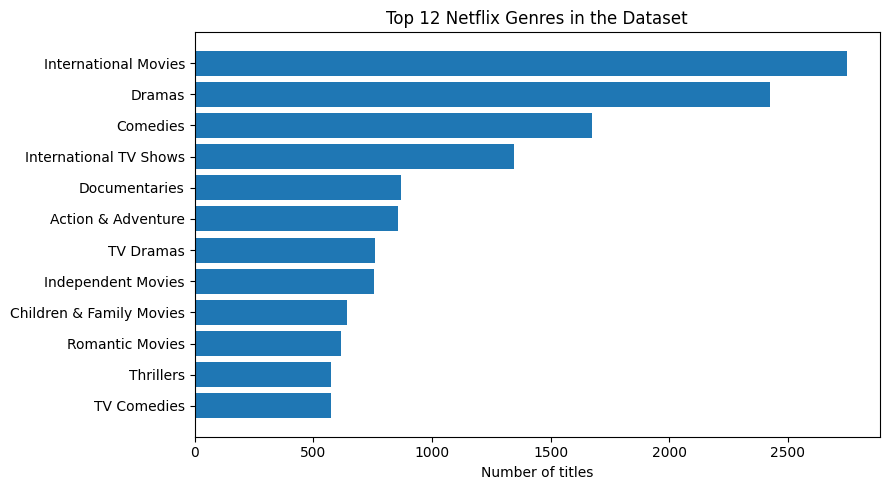

In [5]:
genre_counts = Counter()
for value in data["listed_in"]:
    for genre in _split_values(value):
        genre_counts[genre] += 1

top_genres = pd.DataFrame(genre_counts.most_common(12), columns=["Genre", "Title count"])
display(top_genres)
top_genres.to_csv(OUTPUT_DIR / "top_genres.csv", index=False)

plot_data = top_genres.sort_values("Title count")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_data["Genre"], plot_data["Title count"])
ax.set_title("Top 12 Netflix Genres in the Dataset")
ax.set_xlabel("Number of titles")
fig.tight_layout()
fig.savefig(CHART_DIR / "top_genres.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Build the recommendation function

The `recommend()` method accepts a title and a requested number of suggestions. It calculates cosine similarity between the selected title's TF-IDF vector and all title vectors, removes the selected title from the results, and returns the highest-scoring matches.

In [6]:
def recommend_titles(title: str, number_of_recommendations: int = 10) -> pd.DataFrame:
    """Display the most similar Netflix titles for a selected title."""
    results = recommender.recommend(title, top_n=number_of_recommendations)
    display(results)
    return results

# Example query — change this title to try another item from the dataset.
selected_title = "The Conjuring"
conjuring_results = recommend_titles(selected_title, number_of_recommendations=10)

,rank,title,type,release_year,listed_in,director,country,similarity_score
0,1,Insidious,Movie,2010,"Horror Movies, Thrillers",James Wan,United States,0.9654
1,2,The Conjuring 2,Movie,2016,Horror Movies,James Wan,Canada,0.8657
2,3,Kanika,Movie,2017,"Horror Movies, International Movies, Thrillers",NaN,India,0.5628
3,4,Green Room,Movie,2015,"Horror Movies, Thrillers",Jeremy Saulnier,United States,0.4398
4,5,Knock Knock,Movie,2015,"Horror Movies, Thrillers",Eli Roth,United States,0.4334
5,6,Hush,Movie,2016,"Horror Movies, Thrillers",Mike Flanagan,United States,0.4273
6,7,13 Sins,Movie,2014,"Horror Movies, Thrillers",Daniel Stamm,United States,0.4254
7,8,"As Above, So Below",Movie,2014,"Horror Movies, Thrillers",John Erick Dowdle,United States,0.4254
8,9,Final Destination 2,Movie,2003,"Horror Movies, Thrillers",David R. Ellis,United States,0.4231
9,10,The Charnel House,Movie,2016,"Horror Movies, Thrillers",Craig Moss,United States,0.4144


### Similarity score visualization

A score closer to 1 indicates stronger metadata similarity in this model. It is not a probability, rating, or measure of audience popularity.

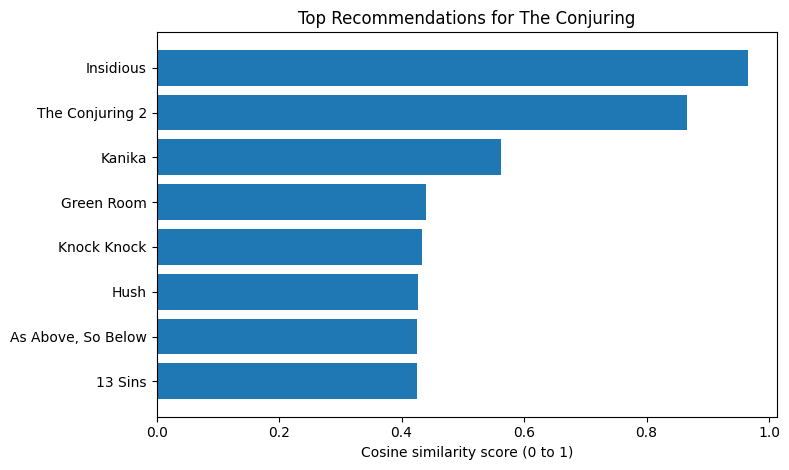

In [7]:
plot_results = conjuring_results.head(8).sort_values("similarity_score")
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(plot_results["title"], plot_results["similarity_score"])
ax.set_title("Top Recommendations for The Conjuring")
ax.set_xlabel("Cosine similarity score (0 to 1)")
fig.tight_layout()
fig.savefig(CHART_DIR / "conjuring_recommendation_scores.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. Try recommendations for other titles

The sample queries below demonstrate that the same recommender works for both TV shows and movies.

In [8]:
sample_queries = ["Stranger Things", "The Conjuring", "Extraction"]
all_sample_results = []

for query in sample_queries:
    print(f"\nRecommendations for: {query}")
    results = recommender.recommend(query, top_n=10)
    display(results)
    results.insert(0, "query_title", query)
    all_sample_results.append(results)

sample_recommendations = pd.concat(all_sample_results, ignore_index=True)
sample_recommendations.to_csv(OUTPUT_DIR / "sample_recommendations.csv", index=False)
print("Saved sample recommendations to outputs/sample_recommendations.csv")


Recommendations for: Stranger Things


,rank,title,type,release_year,listed_in,director,country,similarity_score
0,1,Nightflyers,TV Show,2018,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",NaN,United States,0.9671
1,2,Helix,TV Show,2015,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",NaN,United States,0.9671
2,3,Chilling Adventures of Sabrina,TV Show,2020,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",NaN,United States,0.9533
3,4,Manifest,TV Show,2021,"TV Dramas, TV Mysteries, TV Sci-Fi & Fantasy",NaN,United States,0.7537
4,5,The OA,TV Show,2019,"TV Dramas, TV Mysteries, TV Sci-Fi & Fantasy",NaN,United States,0.7518
5,6,Anjaan: Special Crimes Unit,TV Show,2018,"International TV Shows, TV Horror, TV Mysteries",NaN,India,0.7462
6,7,Scream,TV Show,2019,"Crime TV Shows, TV Horror, TV Mysteries",NaN,United States,0.7432
7,8,The Messengers,TV Show,2015,"TV Dramas, TV Mysteries, TV Sci-Fi & Fantasy",NaN,United States,0.7382
8,9,Typewriter,TV Show,2019,"International TV Shows, TV Horror, TV Mysteries",NaN,India,0.7336
9,10,The Guest,TV Show,2018,"International TV Shows, TV Horror, TV Mysteries",NaN,South Korea,0.7333



Recommendations for: The Conjuring


,rank,title,type,release_year,listed_in,director,country,similarity_score
0,1,Insidious,Movie,2010,"Horror Movies, Thrillers",James Wan,United States,0.9654
1,2,The Conjuring 2,Movie,2016,Horror Movies,James Wan,Canada,0.8657
2,3,Kanika,Movie,2017,"Horror Movies, International Movies, Thrillers",NaN,India,0.5628
3,4,Green Room,Movie,2015,"Horror Movies, Thrillers",Jeremy Saulnier,United States,0.4398
4,5,Knock Knock,Movie,2015,"Horror Movies, Thrillers",Eli Roth,United States,0.4334
5,6,Hush,Movie,2016,"Horror Movies, Thrillers",Mike Flanagan,United States,0.4273
6,7,13 Sins,Movie,2014,"Horror Movies, Thrillers",Daniel Stamm,United States,0.4254
7,8,"As Above, So Below",Movie,2014,"Horror Movies, Thrillers",John Erick Dowdle,United States,0.4254
8,9,Final Destination 2,Movie,2003,"Horror Movies, Thrillers",David R. Ellis,United States,0.4231
9,10,The Charnel House,Movie,2016,"Horror Movies, Thrillers",Craig Moss,United States,0.4144



Recommendations for: Extraction


,rank,title,type,release_year,listed_in,director,country,similarity_score
0,1,First Kill,Movie,2017,Action & Adventure,Steven C. Miller,United Kingdom,0.9533
1,2,Marauders,Movie,2016,Action & Adventure,Steven C. Miller,Canada,0.9426
2,3,Polar,Movie,2019,"Action & Adventure, International Movies",NaN,United States,0.3706
3,4,Close,Movie,2019,"Action & Adventure, International Movies",NaN,United Kingdom,0.3294
4,5,Shadow and Bone - The Afterparty,Movie,2021,"Action & Adventure, Comedies, Dramas",NaN,United States,0.3272
5,6,The Darkest Dawn,Movie,2016,"Action & Adventure, Independent Movies, Intern...",NaN,United Kingdom,0.2946
6,7,The Great Battle,Movie,2018,"Action & Adventure, Dramas, International Movies",NaN,South Korea,0.2806
7,8,Abdo Mota,Movie,2012,"Action & Adventure, Dramas, International Movies",NaN,Egypt,0.2799
8,9,Set Up,Movie,2011,Action & Adventure,Mike Gunther,United States,0.2698
9,10,Batman: The Killing Joke,Movie,2016,Action & Adventure,Sam Liu,United States,0.2698


Saved sample recommendations to outputs/sample_recommendations.csv


## 7. Evaluate recommendation relevance

The dataset does not contain user clicks, viewing history, or ground-truth recommendation pairs. It is therefore not possible to calculate genuine user-level precision, recall, or recommendation accuracy from this file alone.

Instead, an intrinsic evaluation is performed on a reproducible random sample of 100 catalog titles. The evaluation checks:

- Mean top-10 cosine similarity
- Mean genre Jaccard overlap (shared genres divided by all distinct genres in the pair)
- Share of recommendations with the same Movie/TV Show type
- Share of recommendations with the same director, among records where director metadata is available

These metrics check metadata consistency, not user satisfaction.

In [9]:
evaluation_summary, evaluation_details = recommender.evaluate(
    sample_size=100,
    top_n=10,
    random_state=42
)

display(evaluation_summary)
evaluation_summary.to_csv(OUTPUT_DIR / "evaluation_summary.csv", index=False)
evaluation_details.to_csv(OUTPUT_DIR / "evaluation_details_100_queries.csv", index=False)

,metric,value,interpretation
0,Queries evaluated,100.000000,Number of catalog titles sampled
1,Mean top-10 cosine similarity,0.568361,Average TF-IDF similarity of recommendations
2,Mean top-10 genre Jaccard overlap,0.817533,Average genre overlap; 1.0 means identical gen...
3,Same content type share in top-10,0.998000,Fraction of recommendations matching Movie/TV ...
4,Same director share when director is known,0.369034,Fraction sharing at least one listed director;...


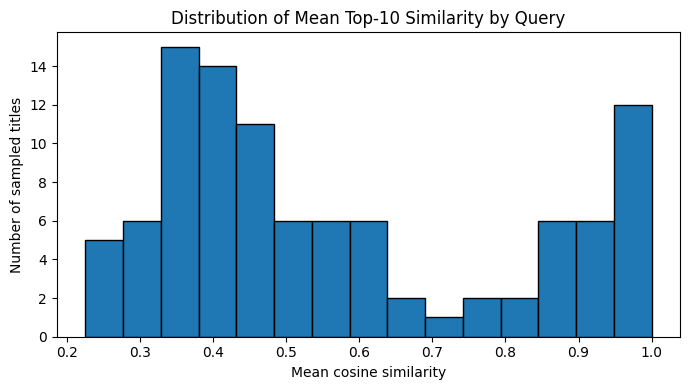

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(evaluation_details["mean_top_n_similarity"], bins=15, edgecolor="black")
ax.set_title("Distribution of Mean Top-10 Similarity by Query")
ax.set_xlabel("Mean cosine similarity")
ax.set_ylabel("Number of sampled titles")
fig.tight_layout()
fig.savefig(CHART_DIR / "evaluation_similarity_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

## 8. Results and conclusion

The model creates a TF-IDF vector for each Netflix title and ranks other titles using cosine similarity. In the sample evaluation of 100 titles, the project reports the following results:

- **Mean top-10 cosine similarity:** approximately 0.5684
- **Mean top-10 genre Jaccard overlap:** approximately 0.8175
- **Same content type share in top 10:** approximately 99.8%
- **Same director share when director is known:** approximately 36.9%

For the example query *The Conjuring*, the closest recommendations include *Insidious* and *The Conjuring 2*.

### Conclusion
The content-based recommendation system successfully suggests similar Netflix titles using the metadata available in the supplied dataset. TF-IDF converts content attributes into numerical vectors, while cosine similarity ranks titles by how closely their metadata matches. The evaluation indicates strong genre overlap and consistent Movie/TV Show matching in the sampled recommendations. Since user interaction data is unavailable, future evaluation with real user feedback would be needed to measure personalization and user satisfaction.

### Generated files
- `outputs/sample_recommendations.csv`
- `outputs/evaluation_summary.csv`
- `outputs/evaluation_details_100_queries.csv`
- `charts/` — generated visualizations
